# Regularizatie met SciKit-Learn

Voorheen hebben we een nieuwe polynomiale feature set gecreëerd en vervolgens onze standaard lineaire regressie daarop toegepast, maar we kunnen ook regularisatie gebruiken om ons model verder te verbeteren.

Regularisatie probeert de RSS (residual sum of squares) plus een penalty te minimaliseren. Deze penalty zal modellen bestraffen die te grote coëfficiënten hebben. Sommige regularisatiemethoden zullen er daadwerkelijk voor zorgen dat features ide geen meerwaarde hebben een coëfficiënt van nul hebben, in welk geval het model de feature niet in overweging neemt.

Laten we twee methoden van regularisatie verkennen: Ridge Regressie en Lasso. We zullen deze combineren met de polynomiale functieset (het zou niet zo effectief zijn om regularisatie van een model uit te voeren op zo'n kleine originele functieset van de oorspronkelijke X).

## Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data en Setup

In [4]:
df = pd.read_csv("Advertising.csv")
X = df.drop('sales',axis=1)
y = df['sales']

### Polynomial Conversion

In [5]:
from sklearn.preprocessing import PolynomialFeatures

In [6]:
polynomial_converter = PolynomialFeatures(degree=3,include_bias=False)

In [7]:
poly_features = polynomial_converter.fit_transform(X)

### Train | Test Split

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=101)

----
----

## Schalen van de data

In [10]:
from sklearn.preprocessing import StandardScaler

In [11]:
# help(StandardScaler)

In [12]:
scaler = StandardScaler()

In [13]:
scaler.fit(X_train)

StandardScaler()

In [14]:
X_train = scaler.transform(X_train)

In [15]:
X_test = scaler.transform(X_test)

## Ridge Regression

In [16]:
from sklearn.linear_model import Ridge

In [17]:
# we starten met een initiële waarde alpha = 10
# Hier kunnen we maar één alpha meegeven!
ridge_model = Ridge(alpha=10)

In [18]:
# fit identiek aan voorheen!
ridge_model.fit(X_train,y_train)

Ridge(alpha=10)

In [19]:
test_predictions = ridge_model.predict(X_test)

In [20]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [21]:
MAE = mean_absolute_error(y_test,test_predictions)
MSE = mean_squared_error(y_test,test_predictions)
RMSE = np.sqrt(MSE)

In [22]:
MAE

0.5774404204714166

In [23]:
RMSE

0.8946386461319656

Hoe presteerde het op de trainingsset? (Dit zal later gebruikt worden ter vergelijking)

In [24]:
# Training Set Performance
train_predictions = ridge_model.predict(X_train)
MAE = mean_absolute_error(y_train,train_predictions)
MAE

0.5288348183025312

### Was deze alpha waarde goed? Bepalen van de alpha waarde door Cross-Validation

In [25]:
# CV wordt zo vaak gebruikt met Ridge Regression dat er een extra versie is!
# Bij CV wordt de gemiddelde fout berekend over de folds
from sklearn.linear_model import RidgeCV

In [26]:
# keuze van de scoring metric
from sklearn.metrics import SCORERS

In [27]:
SCORERS.keys()

dict_keys(['explained_variance', 'r2', 'max_error', 'matthews_corrcoef', 'neg_median_absolute_error', 'neg_mean_absolute_error', 'neg_mean_absolute_percentage_error', 'neg_mean_squared_error', 'neg_mean_squared_log_error', 'neg_root_mean_squared_error', 'neg_mean_poisson_deviance', 'neg_mean_gamma_deviance', 'accuracy', 'top_k_accuracy', 'roc_auc', 'roc_auc_ovr', 'roc_auc_ovo', 'roc_auc_ovr_weighted', 'roc_auc_ovo_weighted', 'balanced_accuracy', 'average_precision', 'neg_log_loss', 'neg_brier_score', 'positive_likelihood_ratio', 'neg_negative_likelihood_ratio', 'adjusted_rand_score', 'rand_score', 'homogeneity_score', 'completeness_score', 'v_measure_score', 'mutual_info_score', 'adjusted_mutual_info_score', 'normalized_mutual_info_score', 'fowlkes_mallows_score', 'precision', 'precision_macro', 'precision_micro', 'precision_samples', 'precision_weighted', 'recall', 'recall_macro', 'recall_micro', 'recall_samples', 'recall_weighted', 'f1', 'f1_macro', 'f1_micro', 'f1_samples', 'f1_weig

In [28]:
# help(RidgeCV)

In [29]:
# Ridge moet weten op basis van welke parameter er moet worden geoptimaliseerd!
# alphas: welke is de best presterende sterkte voor de regularisatie parameter?
# scoring = None: 
# cv: int - hoeveel folds wil je doen in de cross validation? Als je dit weglaat: leave-one-out
# Herinner: negatieve RMSE omdat "Hoger is beter" geldt...
# Alle opties: sklearn.metrics.SCORERS.keys()
# scoring metric is optioneel!
ridge_cv_model = RidgeCV(alphas=(0.01, 0.02, 0.03, 0.04, 0.05, 0.1, 1.0, 10.0),scoring='neg_mean_absolute_error')

# met aantal folds gedefinieerd:
# ridge_cv_model = RidgeCV(alphas=(0.1, 1.0, 10.0),cv=10, scoring='neg_mean_absolute_error')

In [30]:
# Hoe meer waarden voor alpha je doorgeeft, hoe langer dit zal duren...
# Onze dataset is klein dus dit is nog geen probleem!
# Hyperparameter tuning ENKEL op de train set!
ridge_cv_model.fit(X_train,y_train)

RidgeCV(alphas=(0.01, 0.02, 0.03, 0.04, 0.05, 0.1, 1.0, 10.0),
        scoring='neg_mean_absolute_error')

In [31]:
# wat was de beste alpha?
ridge_cv_model.alpha_

0.03

In [32]:
# de test set is hier een soort hold out test set aangezien we er niet op hebben getuned!
test_predictions = ridge_cv_model.predict(X_test)

In [33]:
MAE = mean_absolute_error(y_test,test_predictions)
MSE = mean_squared_error(y_test,test_predictions)
RMSE = np.sqrt(MSE)

In [34]:
MAE

0.4096224723482287

In [35]:
RMSE

0.5901038129101599

In [36]:
# Training Set Performance
# Training Set Performance
train_predictions = ridge_cv_model.predict(X_train)
MAE = mean_absolute_error(y_train,train_predictions)
MAE

0.2901312362573289

In [37]:
ridge_cv_model.coef_

array([ 6.43507716,  0.52705718,  0.33934369, -8.61654588,  4.95591969,
       -1.53915625, -1.29091779,  0.70904477,  0.19458354,  3.96348164,
       -1.51058741,  1.26854012,  0.51645572, -0.30047744,  0.08424225,
        0.6531423 , -0.27979037, -0.16265522, -0.18484187])


-----

## LASSO - least absolute shrinkage and selection operator

In [38]:
# je kan ook gewoon Lasso importeren, waarbij je dan zelf een alpha moet geven!
# je weet normaal de beste alpha waarde niet, dus voer je beter cross validation uit
from sklearn.linear_model import LassoCV

In [39]:
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html
# eps: ratio tussen min en max alpha waarde
# n_alphas: aantal alphas die worden gecontroleerd
# cv: # folds in k-fold cross validation
lasso_cv_model = LassoCV(eps=0.001,n_alphas=100,cv=5)

In [40]:
lasso_cv_model.fit(X_train,y_train)

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.870e+00, tolerance: 3.684e-01
  model = cd_fast.enet_coordinate_descent(


LassoCV(cv=5)

In [41]:
# deze warning zegt dat de zoektocht naar de beste waarde voor alpha niet succesvol was.  
# Je kan dit fixen door meer iteraties: max_iter=1000

In [42]:
lasso_cv_model = LassoCV(eps=0.001,n_alphas=100,cv=5, max_iter=1000000)

In [43]:
lasso_cv_model.fit(X_train,y_train)

LassoCV(cv=5, max_iter=1000000)

In [44]:
# een andere manier om dit te fixen: niet zo breed zoeken inzake de alphas.  Stel eps=0.1
lasso_cv_model = LassoCV(eps=0.1,n_alphas=100,cv=5, max_iter=1000)
lasso_cv_model.fit(X_train,y_train)

LassoCV(cv=5, eps=0.1)

In [45]:
# Wat was nu de beste alpha value?
lasso_cv_model.alpha_

0.4943070909225832

In [46]:
# laat model voorspellen!
test_predictions = lasso_cv_model.predict(X_test)

In [47]:
MAE = mean_absolute_error(y_test,test_predictions)
MSE = mean_squared_error(y_test,test_predictions)
RMSE = np.sqrt(MSE)

In [48]:
MAE

0.6541723161252866

In [49]:
RMSE

1.1308001022762546

In [50]:
# Training Set Performance
# Training Set Performance
train_predictions = lasso_cv_model.predict(X_train)
MAE = mean_absolute_error(y_train,train_predictions)
MAE

0.6912807140820707

* Meervoudige Lineair Regressie:
    * MAE: 1.213
    * RMSE: 1.516

* Polynomial 2-degree:
    * MAE: 0.4896
    * RMSE: 0.664
    
* Ridge 3-degree:
    * MAE: 0.29
    * RMSE: 0.59
    
* Lasso 3-degree met de constraints die we gaven:
    * MAE: 0.65
    * RMSE: 1.13

In [51]:
# Gegeven de constraints aan het model presteert lasso niet zo goed als ridge. Wat is dan het voordeel van lasso?
# Bekijk even de coëfficiënten:

In [52]:
lasso_cv_model.coef_

array([1.002651  , 0.        , 0.        , 0.        , 3.79745279,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        ])

## Elastic Net

Elastic Net combineert de penalties van ridge regression en lasso in een poging het beste van beide te krijgen.  

In [53]:
from sklearn.linear_model import ElasticNetCV

In [54]:
elastic_model = ElasticNetCV()

In [55]:
# l1_ratio: de ratio tussen L1 en L2 regularisatie. Geeft de "hoeveelheid lasso"
# dit komt overeen met de alpha van de formule
# Aangeraden wordt om dicht bij 1 te gaan voor deze parameter.
# eps en n_alphas: zie lasso
# de alphas in n_alphas is de lambda in de formule
# max_iter moeten we misschien ook aanpassen
elastic_model = ElasticNetCV(l1_ratio=[.1, .5, .7,.9, .95, .99, 1],eps=0.001, n_alphas=100, max_iter=1000000)

In [56]:
elastic_model.fit(X_train,y_train)

ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1], max_iter=1000000)

In [57]:
elastic_model.l1_ratio_

1.0

geen ridge, 100% lasso!

In [58]:
test_predictions = elastic_model.predict(X_test)

In [59]:
MAE = mean_absolute_error(y_test,test_predictions)
MSE = mean_squared_error(y_test,test_predictions)
RMSE = np.sqrt(MSE)

In [60]:
MAE

0.43350346185900634

In [61]:
RMSE

0.6063140748984023

In [62]:
# Training Set Performance
# Training Set Performance
train_predictions = elastic_model.predict(X_train)
MAE = mean_absolute_error(y_train,train_predictions)
MAE

0.3307056225674495

In [63]:
elastic_model.coef_

array([ 4.86023329,  0.12544598,  0.20746872, -4.99250395,  4.38026519,
       -0.22977201, -0.        ,  0.07267717, -0.        ,  1.77780246,
       -0.69614918, -0.        ,  0.12044132, -0.        , -0.        ,
       -0.        ,  0.        ,  0.        , -0.        ])

Dit lasso model presteert beter dan het vorige, omdat de overige parameters het model toelieten om verder te zoeken...

-----
---

In [64]:
from sklearn.linear_model import Lasso

train_r2 = []
test_r2 = []
alphas = np.logspace(-4, 1, 10000)

for alpha in alphas:
    this_model = Lasso(alpha=alpha,tol=0.0001,fit_intercept=True, max_iter=1000000)
    this_model.fit(X_train,y_train)         
    test_r2.append(this_model.score(X_test,y_test))
    train_r2.append(this_model.score(X_train,y_train))

/tmp/ipykernel_196544/2485186157.py:3: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(2, 1, 1)


Text(0, 0.5, 'R² Performance')

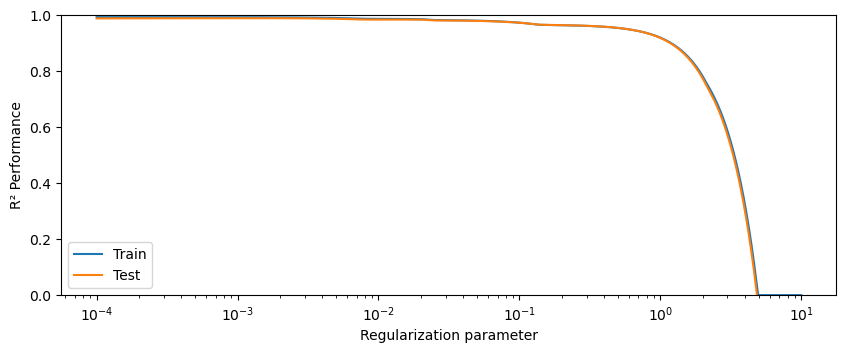

In [65]:
# Plot r2
f, ax = plt.subplots(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.semilogx(alphas, train_r2, label='Train')
plt.semilogx(alphas, test_r2, label='Test')
plt.legend(loc='lower left')
plt.ylim([0, 1])
plt.xlabel('Regularization parameter')
plt.ylabel('R² Performance')

## Subset selection

In [66]:
## Subset selection met cross validation
import itertools
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

def best_subset_selection(X, y, k_fold=5):
    # Predictors
    n_predictors = X.shape[1]
    predictors = X.columns
    # Initialiseer de beste score als - oneindig
    best_score = float('-inf')
    best_subset = []

    # Loop door elk mogelijk aantal predictors
    for k in range(1, n_predictors + 1):
        # Maak alle subsets die mogelijk zijn door 'k' elementen uit de set predictors te kiezen (binomiaalcoëfficiënt)
        subsets = itertools.combinations(predictors, k)
        # ga nu door elk van deze subsets met k elementen heen, en bewaar de beste subset
        for subset in subsets:
            # Fit model en cross-validate
            model = LinearRegression()
            subset = list(subset) 
            scores = cross_val_score(model, X[subset], y, cv=k_fold, scoring='neg_mean_squared_error') # train het model met de subset en return score per fold
            score = scores.mean()

            # Update best score and best subset
            if score > best_score:
                print(f"New best subset: {subset} with score {score}")
                best_score = score
                best_subset = subset

    return best_subset, best_score

In [74]:
# opnieuw naar 9 features (geen regularisatie)
df = pd.read_csv("Advertising.csv")
X = df.drop('sales',axis=1)
y = df['sales']

In [76]:
polynomial_converter = PolynomialFeatures(degree=2,include_bias=False)

In [77]:
poly_features = polynomial_converter.fit_transform(X)

In [78]:
X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=101)

In [80]:
scaler = StandardScaler()
scaler.fit(X_train)
scaler.transform(X_train)
scaler.transform(X_test)

array([[-9.13394717e-01,  1.76259419e+00,  6.81685579e-01,
        -9.63975055e-01,  1.52122095e-02, -2.93048209e-01,
         2.31532893e+00,  1.56001049e+00,  3.69910106e-01],
       [ 1.23121149e+00,  2.36559587e-01, -1.19601922e+00,
         1.38103193e+00,  9.76521639e-01, -6.80562258e-01,
        -5.79325829e-02, -7.40162021e-01, -7.79189389e-01],
       [-4.60024728e-01, -4.07766136e-01,  3.50051150e-01,
        -6.82242743e-01, -5.06457342e-01, -1.10940195e-01,
        -6.39722074e-01, -1.69172158e-01,  3.57554301e-02],
       [-4.96816533e-01,  1.65407618e+00,  9.47927303e-01,
        -7.09383526e-01,  4.86260118e-01,  1.37061544e-01,
         2.10033570e+00,  1.77735495e+00,  6.78908133e-01],
       [-1.42610633e+00,  8.05649381e-02, -1.35015916e+00,
        -1.14433859e+00, -8.66050574e-01, -9.38134722e-01,
        -2.21679679e-01, -8.42466779e-01, -7.93375596e-01],
       [-1.56971305e+00, -5.02719400e-01, -4.11306765e-01,
        -1.16855131e+00, -1.00646472e+00, -8.680574

In [72]:
type(X_train)

numpy.ndarray

In [81]:
# maak een pandas dataframe van de numpy ndarray
columns = ['TV', 'radio', 'newspaper', 'TV*TV', 'TV*radio', 'TV*newspaper', 'radio*radio', 'radio*newspaper', 'newspaper*newspaper']
X_df = pd.DataFrame(X_train, columns=columns)

# call de functie
best_subset, best_score = best_subset_selection(X_df, y_train)
print(f"Best subset: {best_subset}")
print(f"Best cross-validated MSE: {best_score}")

New best subset: ['TV'] with score -10.695488978724427
New best subset: ['TV*radio'] with score -1.9245457480238422
New best subset: ['TV', 'TV*radio'] with score -0.944057847434238
New best subset: ['TV', 'TV*TV', 'TV*radio'] with score -0.46019042149747014
New best subset: ['TV', 'radio', 'TV*TV', 'TV*radio'] with score -0.4316518619385916
New best subset: ['TV', 'TV*TV', 'TV*radio', 'radio*radio'] with score -0.4273868235543635
New best subset: ['TV', 'TV*TV', 'TV*radio', 'radio*newspaper'] with score -0.41303309027134993
New best subset: ['TV', 'newspaper', 'TV*TV', 'TV*radio', 'radio*newspaper'] with score -0.40941645478812083
New best subset: ['TV', 'TV*TV', 'TV*radio', 'TV*newspaper', 'radio*newspaper'] with score -0.39715515951908886
Best subset: ['TV', 'TV*TV', 'TV*radio', 'TV*newspaper', 'radio*newspaper']
Best cross-validated MSE: -0.39715515951908886


In [327]:
# X_df.head()

In [314]:
# Train het model opnieuw op X_train data met de beste subset

(140,)


In [91]:
X_df.head()

,TV,radio,newspaper,TV*TV,TV*radio,TV*newspaper,radio*radio,radio*newspaper,newspaper*newspaper
0,193.2,18.4,65.7,37326.24,3554.88,12693.24,338.56,1208.88,4316.49
1,287.6,43.0,71.8,82713.76,12366.80,20649.68,1849.00,3087.40,5155.24
2,80.2,0.0,9.2,6432.04,0.00,737.84,0.00,0.00,84.64
3,182.6,46.2,58.7,33342.76,8436.12,10718.62,2134.44,2711.94,3445.69
4,222.4,4.3,49.8,49461.76,956.32,11075.52,18.49,214.14,2480.04


In [82]:
X_df[best_subset].head()

,TV,TV*TV,TV*radio,TV*newspaper,radio*newspaper
0,193.2,37326.24,3554.88,12693.24,1208.88
1,287.6,82713.76,12366.80,20649.68,3087.40
2,80.2,6432.04,0.00,737.84,0.00
3,182.6,33342.76,8436.12,10718.62,2711.94
4,222.4,49461.76,956.32,11075.52,214.14


In [83]:
model = LinearRegression()

In [84]:
model.fit(X_df[best_subset], y_train)

LinearRegression()

In [85]:
# convert X_test to dataframe

X_test_df = pd.DataFrame(X_test, columns=columns)

y_pred = model.predict(X_test_df[best_subset])

In [86]:
MAE = mean_absolute_error(y_test, y_pred)
MAE

0.5060704629021674

In [87]:
MSE = mean_squared_error(y_test, y_pred)
MSE

0.47807222623041573

In [88]:
RMSE = np.sqrt(MSE)
RMSE

0.6914276724505721

## Stepwise selection - forward selection

In [89]:
def forward_selection(X, y, k_fold):
    remaining_features = list(X.columns)
    best_subset = []
    best_score = float('inf')  # initialiseer met positief oneindig
    
    while remaining_features:
        scores_with_candidates = []

        for candidate in remaining_features:
            model = LinearRegression()
            scores = cross_val_score(model, X[best_subset + [candidate]], y, cv=k_fold, scoring='neg_mean_squared_error')
            score = -scores.mean()  # Negatief omdat de score die cross_val_score returns negatief is
            scores_with_candidates.append((score, candidate))

        # Sorteer oplopend omdat een lagere MSE beter is
        scores_with_candidates.sort()
        
        # Check of we een nieuwe beste subset hebben gevonden
        if scores_with_candidates[0][0] < best_score:
            best_score = scores_with_candidates[0][0]
            best_subset.append(scores_with_candidates[0][1])
            remaining_features.remove(scores_with_candidates[0][1])
            print(f"New best subset: {best_subset} with MSE {best_score}")
        else:
            # Break indien geen verbetering ("early stopping")
            break

    return best_score, best_subset

In [90]:
best_score, best_subset = forward_selection(X_df, y_train, 5)

New best subset: ['TV*radio'] with MSE 1.9245457480238422
New best subset: ['TV*radio', 'TV'] with MSE 0.9440578474342372
New best subset: ['TV*radio', 'TV', 'TV*TV'] with MSE 0.4601904214975147
New best subset: ['TV*radio', 'TV', 'TV*TV', 'radio*newspaper'] with MSE 0.4130330902714074
New best subset: ['TV*radio', 'TV', 'TV*TV', 'radio*newspaper', 'TV*newspaper'] with MSE 0.3971551595190953
